## Predict the diffusivity w.r.t Density and Temperature, $D(\rho^*,T^*)$

In [2]:
import numpy as np
import torch
from torch import nn
import torchvision
import matplotlib.pyplot as plt
%matplotlib inline
from torch.utils.tensorboard import SummaryWriter
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import datetime
import random

In [8]:
diff_arr = np.loadtxt('diff2darr.txt')
print(diff_arr)

[[1.00000000e-01 5.00000000e-02 1.68522652e-02]
 [2.00000000e-01 5.00000000e-02 2.58511198e-02]
 [3.00000000e-01 5.00000000e-02 3.31655636e-02]
 [4.00000000e-01 5.00000000e-02 3.71987242e-02]
 [5.00000000e-01 5.00000000e-02 4.22037788e-02]
 [6.00000000e-01 5.00000000e-02 4.78776575e-02]
 [7.00000000e-01 5.00000000e-02 5.47761436e-02]
 [8.00000000e-01 5.00000000e-02 5.62865008e-02]
 [9.00000000e-01 5.00000000e-02 6.24190957e-02]
 [1.00000000e+00 5.00000000e-02 6.45991879e-02]
 [1.10000000e+00 5.00000000e-02 7.14526458e-02]
 [1.20000000e+00 5.00000000e-02 7.31222338e-02]
 [1.30000000e+00 5.00000000e-02 7.40526562e-02]
 [1.40000000e+00 5.00000000e-02 7.72238147e-02]
 [1.50000000e+00 5.00000000e-02 7.94266791e-02]
 [1.60000000e+00 5.00000000e-02 8.90472928e-02]
 [1.70000000e+00 5.00000000e-02 8.87610126e-02]
 [1.80000000e+00 5.00000000e-02 9.06170027e-02]
 [1.90000000e+00 5.00000000e-02 9.71602356e-02]
 [2.00000000e+00 5.00000000e-02 1.02913034e-01]
 [2.10000000e+00 5.00000000e-02 1.042486

In [4]:
indices = range(0,240)
rand_indices = random.sample(indices, 160)

print(rand_indices)
training_set = []
testing_set = []
for i in range(240):
    #print(i)
    if i in rand_indices:
        training_set.append(diff_arr[i])
    else:
        testing_set.append(diff_arr[i])

[30, 96, 231, 147, 221, 138, 5, 183, 99, 62, 139, 7, 232, 193, 80, 133, 112, 97, 106, 157, 156, 166, 28, 23, 198, 8, 98, 49, 161, 56, 109, 182, 24, 127, 104, 170, 81, 108, 118, 210, 188, 18, 21, 150, 125, 128, 16, 196, 229, 43, 84, 78, 180, 15, 12, 207, 123, 184, 47, 70, 200, 19, 159, 217, 59, 151, 137, 119, 223, 238, 27, 226, 111, 79, 168, 214, 199, 155, 100, 140, 201, 171, 88, 110, 219, 77, 73, 4, 113, 50, 131, 44, 169, 105, 116, 101, 174, 57, 29, 142, 187, 75, 114, 92, 145, 215, 32, 121, 179, 58, 10, 6, 60, 31, 230, 71, 141, 54, 148, 20, 14, 33, 103, 208, 164, 235, 55, 206, 94, 136, 163, 64, 87, 130, 143, 66, 68, 120, 189, 26, 181, 220, 176, 13, 190, 86, 45, 228, 205, 146, 67, 89, 237, 153, 165, 115, 129, 126, 90, 39]


In [5]:
training_set = np.array(training_set)
T_train_np = training_set[:,0]
rho_train_np = training_set[:,1]
D_train_np = training_set[:,2]

testing_set = np.array(testing_set)
T_test_np = testing_set[:,0]
rho_test_np = testing_set[:,1]
D_test_np = testing_set[:,2]


In [6]:
T_train = torch.from_numpy(T_train_np)
rho_train = torch.from_numpy(rho_train_np)
D_train = torch.from_numpy(D_train_np)

T_test = torch.from_numpy(T_test_np)
rho_test = torch.from_numpy(rho_test_np)
D_test = torch.from_numpy(D_test_np)


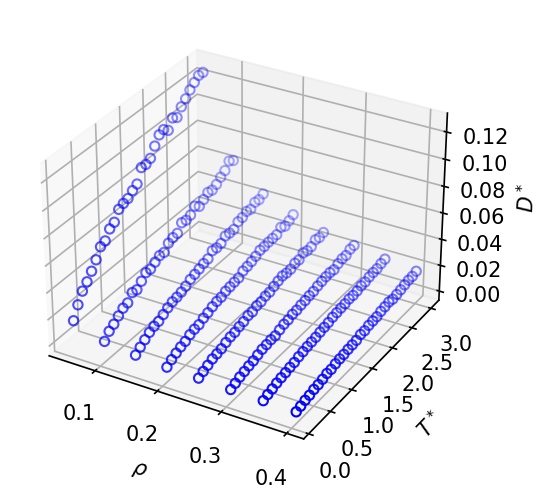

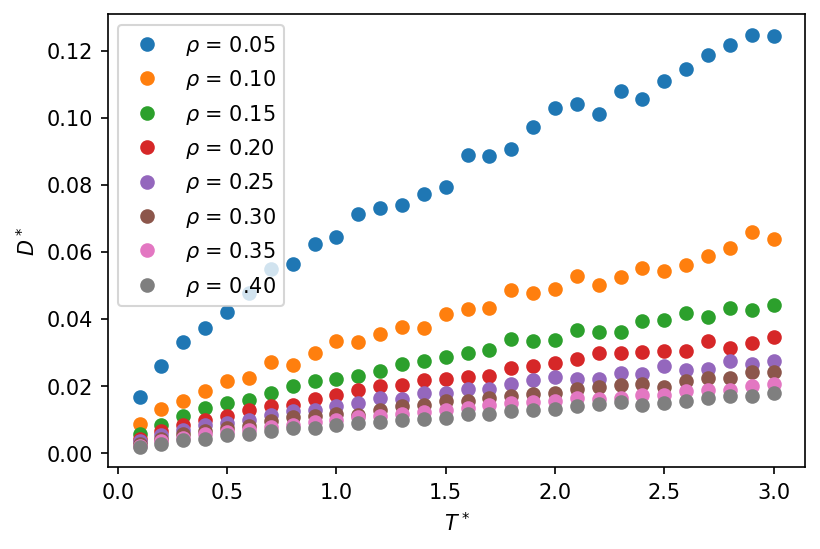

ValueError: array split does not result in an equal division

In [7]:
fig_id = 1
plt.rcParams['figure.dpi'] = 150 
fig = plt.figure(fig_id)

ax = fig.add_subplot(111, projection='3d')
ax.scatter(diff_arr[:,1], diff_arr[:,0], diff_arr[:,2],facecolors='none', edgecolors='b')
ax.set_xlabel(r"$\rho$")
ax.set_ylabel('$T^*$')
ax.set_zlabel('$D^*$')
plt.show()
fig_id += 1

diff_spl = np.split(diff_arr,8)
plt.rcParams['figure.dpi'] = 150 
fig = plt.figure(fig_id)

for r in range(len(diff_spl)):
    diff_r = diff_spl[r]
    
    labelr =  r"$\rho$ = "+ str(format(diff_r[0,1], '.2f'))
    plt.plot(diff_r[:,0], diff_r[:,2], 'o',label = labelr)
    
plt.xlabel('$T^*$')
plt.ylabel('$D^*$')
plt.legend()
plt.show()
fig_id += 1



In [7]:
class ffnn(nn.Module):
    """basic FF network for approximating functions"""
    def __init__(self, nn_width=10, num_hidden=2):
        super().__init__()
        
        self.layer_first = nn.Linear(2, nn_width)
        
        layers = []
        for _ in range(num_hidden):
            layers.append(nn.Linear(nn_width, nn_width))
        self.layer_hidden = nn.ModuleList(layers)
        
        self.layer_last = nn.Linear(nn_width, 1)
        
    def forward(self, x, y):
        xy = torch.cat((x, y), -1)
        activation = nn.Tanh()
        u = activation(self.layer_first(xy))
        for hidden in self.layer_hidden:
            u = activation(hidden(u))
        u = self.layer_last(u)
        return u

In [8]:
def loss_train(model,T, rho):

    d_p = model(T.float(),rho.float())
    loss = torch.pow(D_train - d_p, 2).mean()
    return 1000*loss

def loss_test(model, rho, T):
    d_p = model(T.float(),rho.float())
    loss = torch.pow(D_test - d_p, 2).mean()
    return 1000*loss

In [9]:
model = ffnn()
lr = 0.01
n_epochs = 20000
opt = torch.optim.Adam(model.parameters(), lr)
loss_train_hist = []
loss_test_hist = []
T_train = T_train.reshape(len(T_train),1)
rho_train = rho_train.reshape(len(rho_train),1)
D_train = D_train.reshape(len(D_train),1)
T_test = T_test.reshape(len(T_test),1)
rho_test = rho_test.reshape(len(rho_test),1)
D_test = D_test.reshape(len(D_test),1)

In [10]:
print(T_train.shape)
print(len(rho_train))

torch.Size([160, 1])
160


In [11]:
for i in range(n_epochs):
    loss_i = loss_train(model, T_train, rho_train)
    loss_test_i = loss_test(model,T_test, rho_test)
    opt.zero_grad()
    loss_train_hist.append(loss_i.item())
    loss_test_hist.append(loss_test_i.item())
    loss_i.backward()
    opt.step()
    
    if i % 100 == 0 or i == n_epochs-1:
        print(f'epoch {i}, loss = {loss_i}, loss_test = {loss_test_i}')

epoch 0, loss = 11.933301089004125, loss_test = 28.082687471931166
epoch 100, loss = 0.22232282232264008, loss_test = 26.038660866642793
epoch 200, loss = 0.19591419795854684, loss_test = 19.125799845524533
epoch 300, loss = 0.16725248460000533, loss_test = 9.14643115650377
epoch 400, loss = 0.1445033646212285, loss_test = 1.6804857379854456
epoch 500, loss = 0.15372390600209657, loss_test = 0.789433083405989
epoch 600, loss = 0.07424553464639627, loss_test = 4.694671302919682
epoch 700, loss = 0.049368614288023804, loss_test = 7.645692630743157
epoch 800, loss = 0.041416754278330574, loss_test = 3.6658879293564364
epoch 900, loss = 0.0330637443963832, loss_test = 1.3367083143402352
epoch 1000, loss = 0.02424729244384265, loss_test = 0.5748462034688434
epoch 1100, loss = 0.01918637331207624, loss_test = 0.7135563509230601
epoch 1200, loss = 0.013436109306316203, loss_test = 1.2709561596945411
epoch 1300, loss = 0.00964403889146803, loss_test = 1.9561348821485474
epoch 1400, loss = 0.00

epoch 11400, loss = 0.0011512704087987232, loss_test = 1.233411033565676
epoch 11500, loss = 0.0009661355906570385, loss_test = 1.234604756042176
epoch 11600, loss = 0.000880638285326581, loss_test = 1.2400885205110252
epoch 11700, loss = 0.0008392148262133637, loss_test = 1.2467877438253048
epoch 11800, loss = 0.0008161938095279591, loss_test = 1.2542813859487585
epoch 11900, loss = 0.0008009719382833801, loss_test = 1.2628118006132973
epoch 12000, loss = 0.0007893713524594686, loss_test = 1.272563774768088
epoch 12100, loss = 0.0007797170182486471, loss_test = 1.2835460519414663
epoch 12200, loss = 0.0007712815673101728, loss_test = 1.2956672491600782
epoch 12300, loss = 0.0007637229207059678, loss_test = 1.3087615802783823
epoch 12400, loss = 0.0007568525636370134, loss_test = 1.3226518424180127
epoch 12500, loss = 0.0007505719506736846, loss_test = 1.3371533886915936
epoch 12600, loss = 0.0007792786226519818, loss_test = 1.1798816360011366
epoch 12700, loss = 0.0007478527916377696,

In [12]:
d_p_train = model(T_train.float(),rho_train.float())
d_p_test = model(T_test.float(), rho_test.float())


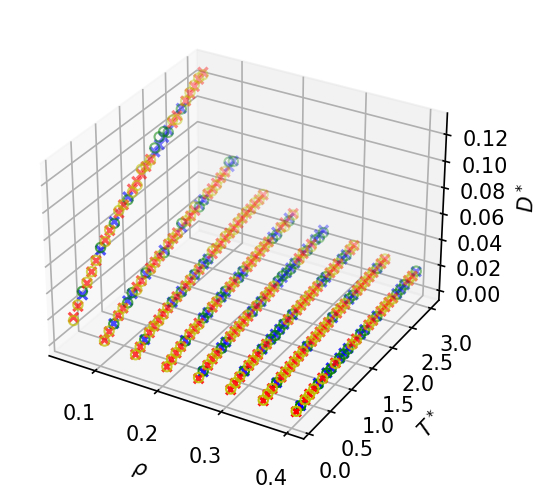

In [13]:
plt.rcParams['figure.dpi'] = 150 
fig = plt.figure(fig_id)

ax = fig.add_subplot(111, projection='3d')
ax.scatter(rho_train_np, T_train_np, D_train_np, facecolors='none', edgecolors='y',label = 'Training Data')
ax.scatter(rho_train_np, T_train_np, d_p_train.detach().numpy() ,marker='x',c='r', label="Training Prediction")
ax.scatter(rho_test_np, T_test_np, D_test_np, facecolors='none', edgecolors='g',label = 'Testing Data')
ax.scatter(rho_test_np, T_test_np, d_p_test.detach().numpy() ,marker='x',c='b', label="Training Prediction")
ax.set_xlabel(r"$\rho$")
ax.set_ylabel('$T^*$')
ax.set_zlabel('$D^*$')
plt.show()
fig_id += 1

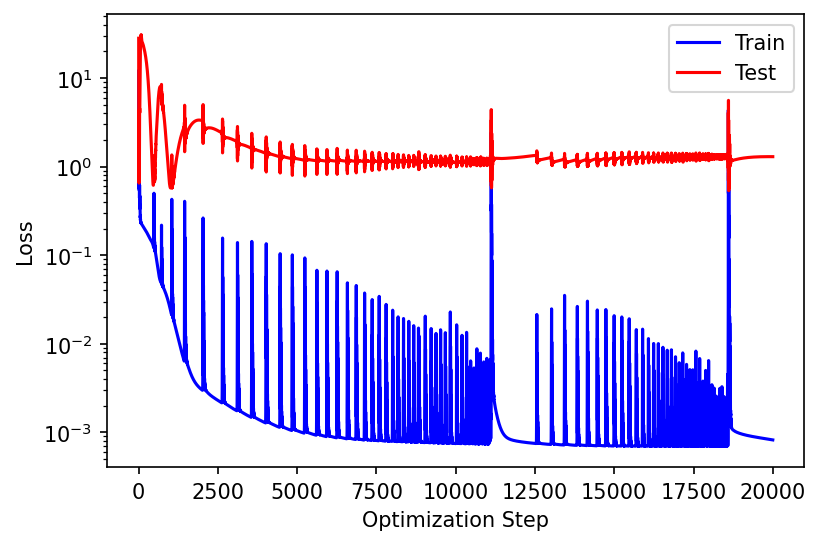

In [14]:
plt.rcParams['figure.dpi'] = 150 
fig = plt.figure(fig_id)

plt.semilogy(loss_train_hist,'b',label = 'Train')
plt.semilogy(loss_test_hist,'r',label = 'Test')
plt.xlabel('Optimization Step')
plt.ylabel('Loss')
plt.legend()
fig_id += 1

In [82]:
print(diff_spl[0][:,0])
print(diff_spl[0][0,1])
print(diff_spl[0][:,2])

[0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8
 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9 3. ]
0.05
[0.01685227 0.02585112 0.03316556 0.03719872 0.04220378 0.04787766
 0.05477614 0.0562865  0.0624191  0.06459919 0.07145265 0.07312223
 0.07405266 0.07722381 0.07942668 0.08904729 0.08876101 0.090617
 0.09716024 0.10291303 0.10424869 0.10113626 0.10787938 0.10570074
 0.11113107 0.11461695 0.11874133 0.12187622 0.12470614 0.12454975]
